In [1]:
import numpy as np

# Four deliveries A, B, C, D: 1 = late, 0 = on time
actual = np.array([1, 1, 1, 0])
probability_late = np.array([0.9, 0.4, 0.01, 0.2])   # what the model predicted

# The probability the model gave to what actually happened
probability_given_to_actual = np.where(actual == 1, probability_late, 1 - probability_late)

cross_entropy = -np.log(probability_given_to_actual)
squared_error = (actual - probability_late) ** 2

print(probability_given_to_actual)
print(cross_entropy.round(2), cross_entropy.mean().round(2))
print(squared_error.round(2), squared_error.mean().round(2))

[0.9  0.4  0.01 0.8 ]
[0.11 0.92 4.61 0.22] 1.46
[0.01 0.36 0.98 0.04] 0.35


**Pseudo-code**

```
store the 4 deliveries: actual (1 = late) and the predicted probability of late
p given to actual: p if late, 1 − p if on time
cross-entropy = −ln(p given to actual) for each delivery, then the mean
squared error = (actual − p)² for each delivery, then the mean
```

In [3]:
# How hard each loss pushes the score z of each delivery (its slope with respect to z)
slope_cross_entropy = probability_late - actual
slope_squared_error = 2 * (probability_late - actual) * probability_late * (1 - probability_late)

print(slope_cross_entropy.round(4))
print(slope_squared_error.round(4))

[-0.1  -0.6  -0.99  0.2 ]
[-0.018  -0.288  -0.0196  0.064 ]


**Pseudo-code**

```
slope of the cross-entropy with respect to the score z: p − actual
slope of the squared error: 2 × (p − actual) × p × (1 − p)
print both, one value per delivery
```

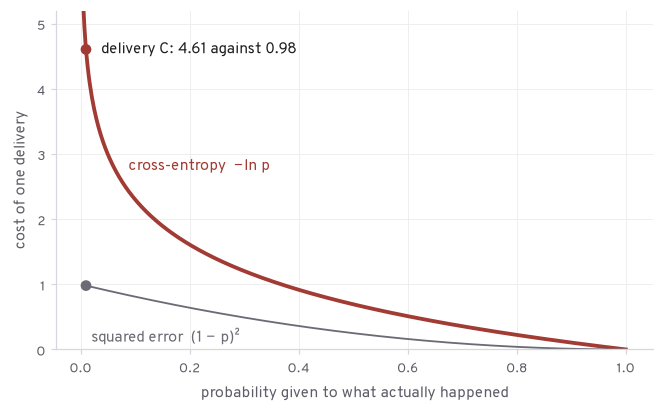

In [4]:
import sys
sys.path.insert(0, "../../../style")
from charte import charger_charte, sauver_clair_et_sombre  # shared style: fonts, colours, light and dark export
import matplotlib.pyplot as plt

charger_charte()

p = np.linspace(0.005, 1, 500)   # probability given to what actually happened

def draw(colours):
    figure, axis = plt.subplots(figsize=(7, 4))
    axis.plot(p, -np.log(p), color=colours["accent"], linewidth=2.5)
    axis.plot(p, (1 - p) ** 2, color=colours["trait"], linewidth=1.2)
    axis.annotate("cross-entropy  −ln p", (0.06, -np.log(0.06)), xytext=(10, 0),
                  textcoords="offset points", va="center", color=colours["accent"])
    axis.annotate("squared error  (1 − p)²", (0.02, 0.12), color=colours["trait"])
    # Delivery C: the model gave 0.01 to what actually happened
    axis.scatter([0.01, 0.01], [-np.log(0.01), (1 - 0.01) ** 2],
                 color=[colours["accent"], colours["trait"]], zorder=3)
    axis.annotate("delivery C: 4.61 against 0.98", (0.01, -np.log(0.01)), xytext=(10, 0),
                  textcoords="offset points", va="center", color=colours["texte"])
    axis.set_ylim(0, 5.2)
    axis.set_xlabel("probability given to what actually happened")
    axis.set_ylabel("cost of one delivery")
    return figure

sauver_clair_et_sombre(draw, "cost_by_probability")

**Pseudo-code**

```
load the shared style (fonts, colours)
p: 500 values between 0.005 and 1
draw −ln(p) in the accent colour, (1 − p)² in grey
mark delivery C (p = 0.01) on both curves
save two versions: _clair.png (light) and _sombre.png (dark)
```